# Optimal lookback for shrunk Sharpe estimates

Concise theory for choosing the lookback window $T$ when Sharpe ratios are estimated with cross-sectional shrinkage and true Sharpes are nonstationary: they drift and their alpha decays.

## 1. Shrinkage under stationarity

Each strategy $k$ has a true Sharpe $\theta_k$ and a $T_k$-year estimate $S_k$, with Sharpes annualized and $T$ in years:

$$
\theta_k \sim (\mu,\ \tau^2), \qquad S_k = \theta_k + \varepsilon_k, \qquad \operatorname{Var}(\varepsilon_k) \approx \frac{1}{T_k}
$$

The shrinkage estimator is

$$
\hat S_k = \langle S\rangle + B_k\,(S_k - \langle S\rangle), \qquad B_k = \frac{T_k}{T_k + T_{\text{prior}}}, \qquad T_{\text{prior}} = \frac{1}{\tau^2}
$$

$T_{\text{prior}}$ is the number of years of track record the cross-sectional prior is worth.

**Why shrinkage helps.** For a fixed weight $B$, the error is a variance–bias trade-off:

$$
\operatorname{MSE}(B) = B^2\,\frac{1}{T} + (1-B)^2\,\tau^2
$$

This is minimized at $B^* = T/(T + T_{\text{prior}})$, which gives

$$
\operatorname{MSE}_{\text{shrunk}} = \frac{1}{T + T_{\text{prior}}} = B^* \cdot \operatorname{MSE}_{\text{raw}}
$$

With 3 or more strategies, James–Stein guarantees shrinkage beats the raw estimates in total MSE. It also removes most of the winner's curse when you select the top strategies.

Under stationarity, a longer lookback is always better. One year of data has noise variance about 1, against a typical signal variance $\tau^2 \approx 0.1$.

## 2. Nonstationarity: drift and decay

The target is the **forward** Sharpe $\theta^* = \theta_{T+h}$, where $h$ is the forecast horizon. Two effects make a $T$-year window stale:

| Effect | Model | Error added to the window estimate | Dependence on $T$ |
|---|---|---|---|
| Drift / regime change | random walk, variance $q$ per year | $q\left(\tfrac{T}{3}+h\right)$ | linear |
| Alpha decay | trend, $g$ Sharpe lost per year | bias $g\left(\tfrac{T}{2}+h\right)$, squared | quadratic |

Each effect splits into a **common** part, shared by all strategies ($q_c$, $\bar g$), and an **idiosyncratic** part ($q$, $\sigma_g$).

The distinction matters because the shrinkage target $\langle S\rangle$ comes from the same window. Shrinkage therefore scales the idiosyncratic errors by $B$, but passes common lag and bias through in full, since $B + (1-B) = 1$.

**Idiosyncratic terms only.** The shrunk MSE becomes $\dfrac{\tau^2 v}{\tau^2 + v}$ with

$$
v(T) = \frac{1}{T} + q\left(\tfrac{T}{3}+h\right) + \sigma_g^2\left(\tfrac{T}{2}+h\right)^2
$$

This is increasing in $v$, so $T^*$ is the minimizer of $v$, the same as without shrinkage:

$$
\text{Drift: } T^* = \sqrt{3/q} \qquad\qquad \text{Decay } (h=0)\text{: } T^* = \left(2/\sigma_g^2\right)^{1/3}
$$

The correct weight under idiosyncratic drift is $B = \tau^2/(\tau^2 + v)$, not $T/(T + T_{\text{prior}})$. The naive weight overweights stale data.

## 3. Full model: common terms, finite $K$, correlated errors

Use $K$ strategies with an equally weighted $\langle S\rangle$. Let estimation errors share a common part with correlation $\rho$:

$$
\varepsilon_j = e_c + u_j, \qquad \operatorname{Var}(e_c) = \frac{\rho}{T}, \qquad \operatorname{Var}(u_j) = \frac{1-\rho}{T}
$$

The optimal weight keeps your form, but the prior is worth fewer years:

$$
B^* = \frac{T}{T + (1-\rho)\,T_{\text{prior}}}
$$

The resulting MSE, verified by Monte Carlo:

$$
\boxed{\operatorname{MSE}^*(T) = \frac{\rho}{T} + \frac{\left(1-\tfrac{1}{K}\right)(1-\rho)}{T + (1-\rho)\,T_{\text{prior}}} + \frac{1-\rho}{K\,T} + q_c\left(\tfrac{T}{3}+h\right) + \bar g^{\,2}\left(\tfrac{T}{2}+h\right)^2}
$$

The terms, in order:

1. Common estimation noise, which shrinkage can't remove.
2. Idiosyncratic noise after shrinkage.
3. Noise in $\langle S\rangle$.
4. Common drift lag.
5. Common decay bias.

Without shrinkage, the MSE is $\dfrac{1}{T} + q_c\left(\tfrac{T}{3}+h\right) + \bar g^{\,2}\left(\tfrac{T}{2}+h\right)^2$.

Define the effective number of independent strategies:

$$
\frac{1}{K_{\text{eff}}} = \rho + \frac{1-\rho}{K}
$$

As $K$ grows, $K_{\text{eff}}$ saturates at $1/\rho$.

## 4. Optimal lookback

The first-order condition $d\operatorname{MSE}^*/dT = 0$ reads

$$
\frac{\rho}{T^2} + \frac{\left(1-\tfrac{1}{K}\right)(1-\rho)}{\big(T + (1-\rho)T_{\text{prior}}\big)^2} + \frac{1-\rho}{K\,T^2}
= \frac{q_c}{3} + \bar g^{\,2}\left(\tfrac{T}{2}+h\right)
$$

The left side is the marginal noise reduction from one more year. The right side is the marginal staleness cost.

**Limiting cases**

| Case | Without shrinkage | With shrinkage ($K=\infty$, $\rho=0$) | With shrinkage, finite $K_{\text{eff}}$, strong prior |
|---|---|---|---|
| Common drift $q_c$ | $\sqrt{3/q_c}$ | $\max\left(0,\ \sqrt{3/q_c} - T_{\text{prior}}\right)$ | floor $\sqrt{3/(K_{\text{eff}}\,q_c)}$ |
| Common decay $\bar g$, $h=0$ | $\left(2/\bar g^{\,2}\right)^{1/3}$ | root of $T\,(T + T_{\text{prior}})^2 = 2/\bar g^{\,2}$ | root of $T^3 = 2/(K_{\text{eff}}\,\bar g^{\,2})$ |
| Idiosyncratic drift or decay | $\sqrt{3/q}$, $\left(2/\sigma_g^2\right)^{1/3}$ | unchanged | unchanged |

What the cases show:

- **Shrinkage shortens the window only through common nonstationarity.** The prior supplies $T_{\text{prior}}$ years of non-stale information about each strategy's deviation from the mean, so extra stale years are worth less.
- **The floor scales with $K_{\text{eff}}$.** Shrinkage can shorten the window by at most a factor of $\sqrt{K_{\text{eff}}}$ (drift) or $K_{\text{eff}}^{1/3}$ (decay).
- **Common decay that you don't model is what forces short windows.** Estimating a time-varying $\mu_t$ removes the common terms, and $T^*$ returns to the long idiosyncratic values.






**Intuition: why shrinkage shortens the optimal lookback**

The lookback trades **noise** against **staleness**. One more year of history reduces sampling noise but adds stale information. $T^*$ is where the marginal noise reduction equals the marginal staleness cost.

**Shrinkage lowers the value of extra data.** Without shrinkage, the error variance is $1/T$, so one more year reduces it by $1/T^2$. With shrinkage, the prior adds $T_{\text{prior}}$ years' worth of non-stale information, so the error variance is $1/(T + T_{\text{prior}})$ and one more year reduces it by only $1/(T + T_{\text{prior}})^2$.

**Shrinkage does not reduce the staleness cost.** Common drift and decay shift every window average, including the target $\langle S\rangle$. The estimate $\hat S_k = (1-B)\langle S\rangle + B\,S_k$ carries the common error with weight $(1-B) + B = 1$.

The benefit of an extra year falls while its cost stays the same, so the optimum moves earlier. For pure common drift, $T^* = \sqrt{3/q_c}$ becomes $\sqrt{3/q_c} - T_{\text{prior}}$.

**Exceptions.** Idiosyncratic drift or decay leaves $T^*$ unchanged, because shrinkage scales a strategy's own noise and staleness by the same factor $B^2$. Common estimation noise (correlation $\rho$) and the finite number of strategies $K$ set a floor, $T^* \ge \sqrt{3/(K_{\text{eff}}\,q_c)}$.


**Estimating the parameters from the panel (approximately):**

| Parameter | Estimator |
|---|---|
| $T_{\text{prior}} = 1/\tau^2$ | $\hat\tau^2 = \operatorname{Var}_k(S_k) - \operatorname{mean}_k(1/T_k)$ |
| $\rho$ | average pairwise correlation of strategy returns |
| $q_c$ (common drift) | $\operatorname{Var}\big(\Delta\langle S\rangle_t\big) - 2/K_{\text{eff}}$, using annual cross-sectional mean Sharpes |
| $\bar g$ (common decay) | time trend of $\langle S\rangle_t$, or decay in event time since launch |
| $q$, $\sigma_g$ (idiosyncratic) | lagged autocovariance of annual Sharpes across strategies; noise drops out at lags $\ge 1$ |


Estimate a time-varying prior mean $\mu_t$ from a short or exponentially weighted cross-sectional window, or from an explicit decay fit. This is worth more than tuning $N$.


## 5. Simulation: Optimal lookback vs common drift and decay, with the RMSE trade-off

In [17]:
import numpy as np
import matplotlib.pyplot as plt

T_GRID = np.arange(0.05, 40.0001, 0.05)

def mse(T, T_prior, q_c, g_bar, h, K, rho, shrink=True):
    """MSE of the forward-Sharpe estimate for lookback T (years)."""
    common = q_c * (T / 3 + h) + g_bar**2 * (T / 2 + h) ** 2
    if not shrink:
        return 1 / T + common
    return (rho / T
            + (1 - 1 / K) * (1 - rho) / (T + (1 - rho) * T_prior)
            + (1 - rho) / (K * T)
            + common)

def optimal_T(T_prior, q_c, g_bar, h, K, rho, shrink=True):
    """Grid-search optimum; returns (T*, RMSE at T*)."""
    v = mse(T_GRID, T_prior, q_c, g_bar, h, K, rho, shrink)
    i = v.argmin()
    return T_GRID[i], np.sqrt(v[i])

def K_eff(K, rho):
    return 1 / (rho + (1 - rho) / K)

# default parameters (same as the interactive simulation)
P = dict(T_prior=11, h=1, K=20, rho=0.05)
print("K_eff =", round(K_eff(P["K"], P["rho"]), 1))
for drift, decay in [(0.1, 0.0), (0.0, 0.03), (0.1, 0.03)]:
    ts, es = optimal_T(q_c=drift**2, g_bar=decay, shrink=True, **P)
    tr, er = optimal_T(q_c=drift**2, g_bar=decay, shrink=False, **P)
    print(f"drift={drift:.2f} decay={decay:.3f}:  shrunk T*={ts:4.1f} RMSE={es:.3f} | raw T*={tr:4.1f} RMSE={er:.3f}")

K_eff = 10.3
drift=0.10 decay=0.000:  shrunk T*= 9.6 RMSE=0.312 | raw T*=17.3 RMSE=0.354
drift=0.00 decay=0.030:  shrunk T*= 7.7 RMSE=0.289 | raw T*=12.4 RMSE=0.357
drift=0.10 decay=0.030:  shrunk T*= 5.6 RMSE=0.340 | raw T*=10.6 RMSE=0.419


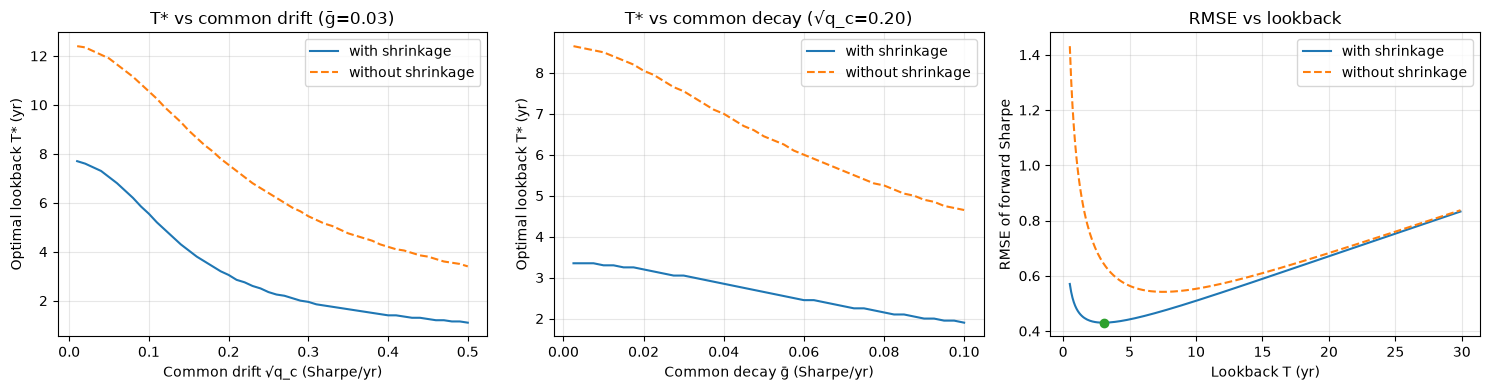

In [15]:
drifts = np.linspace(0.01, 0.5, 50)
decays = np.linspace(0.0025, 0.1, 40)
fig, ax = plt.subplots(1, 3, figsize=(15, 4))

q_c=0.2**2; g_bar=0.03
for shrink, style in [(True, "-"), (False, "--")]:
    lbl = "with shrinkage" if shrink else "without shrinkage"
    ax[0].plot(drifts, [optimal_T(q_c=d**2, g_bar=g_bar, shrink=shrink, **P)[0] for d in drifts], style, label=lbl)
    ax[1].plot(decays, [optimal_T(q_c=q_c, g_bar=g, shrink=shrink, **P)[0] for g in decays], style, label=lbl)
    Ts = np.arange(0.5, 30, 0.1)
    ax[2].plot(Ts, np.sqrt(mse(Ts, P["T_prior"], q_c, g_bar, P["h"], P["K"], P["rho"], shrink)), style, label=lbl)


ts, es = optimal_T(q_c=q_c, g_bar=g_bar, **P)
ax[2].plot(ts, es, "o")
#ax[2].set_ylim(es * 0.9, es * 1.8)
ax[0].set(xlabel="Common drift √q_c (Sharpe/yr)", ylabel="Optimal lookback T* (yr)", title=f"T* vs common drift (ḡ={g_bar:.2f})")
ax[1].set(xlabel="Common decay ḡ (Sharpe/yr)", ylabel="Optimal lookback T* (yr)", title=f"T* vs common decay (√q_c={np.sqrt(q_c):.2f})")
ax[2].set(xlabel="Lookback T (yr)", ylabel="RMSE of forward Sharpe", title="RMSE vs lookback")
for a in ax:
    a.grid(alpha=0.3); a.legend()
plt.tight_layout(); plt.show()

## 6. Interactive simulation

In [29]:
import html as _html, warnings
from IPython.display import HTML, display
warnings.filterwarnings("ignore", message="Consider using IPython.display.IFrame")

SIM_HTML = r'''<!doctype html>
<html lang="en">
<head>
<meta charset="utf-8">
<meta name="viewport" content="width=device-width, initial-scale=1">
<title>Optimal Sharpe Lookback</title>
<style>
:root{--bg:#fcfcfb;--card:#f1efe8;--text:#0b0b0b;--muted:#52514e;--grid:#e1e0d9;--tick:#898781;--ring:#fcfcfb}
@media (prefers-color-scheme: dark){:root{--bg:#1a1a19;--card:#262624;--text:#f0efec;--muted:#c3c2b7;--grid:#2c2c2a;--tick:#898781;--ring:#1a1a19}}
body{margin:0;background:var(--bg);color:var(--text);font-family:system-ui,-apple-system,"Segoe UI",sans-serif}
main{max-width:760px;margin:0 auto;padding:24px 16px 48px}
h1{font-size:22px;font-weight:500;margin:0 0 6px}
p.sub{font-size:14px;color:var(--muted);margin:0 0 20px;line-height:1.6}
.row{display:flex;align-items:center;gap:12px;margin:0 0 10px}
.row label{font-size:13px;color:var(--muted);min-width:230px}
.row input{flex:1;accent-color:#2a78d6}
.row span{font-size:13px;font-weight:500;min-width:48px;text-align:right}
.cards{display:grid;grid-template-columns:repeat(auto-fit,minmax(140px,1fr));gap:12px;margin:18px 0}
.card{background:var(--card);border-radius:8px;padding:12px 14px}
.card p{margin:0;font-size:13px;color:var(--muted)}
.card div{font-size:22px;font-weight:500}
.leg{display:flex;flex-wrap:wrap;gap:16px;font-size:12px;color:var(--muted);margin:16px 0 6px}
.leg span{display:flex;align-items:center;gap:6px}
.sw{width:18px;height:0;border-top:2px solid}
.dot{width:10px;height:10px;border-radius:50%;background:#2a78d6}
.chart{position:relative;width:100%;height:260px;margin-top:18px}
code{font-size:13px}
@media (max-width:560px){.row{flex-wrap:wrap}.row label{min-width:100%}}
</style>
</head>
<body>
<main>
<h1>Optimal lookback for shrunk Sharpe estimates</h1>

<div class="row"><label for="d">Common drift √q_c (Sharpe/yr)</label><input type="range" id="d" min="0" max="0.5" step="0.01" value="0.2"><span id="dO"></span></div>
<div class="row"><label for="g">Common decay ḡ (Sharpe/yr)</label><input type="range" id="g" min="0" max="0.1" step="0.005" value="0.03"><span id="gO"></span></div>
<div class="row"><label for="h">Forecast horizon h (yr)</label><input type="range" id="h" min="0" max="5" step="0.05" value="0.25"><span id="hO"></span></div>
<div class="row"><label for="t">T_prior (yr)</label><input type="range" id="t" min="0.5" max="30" step="0.5" value="10"><span id="tO"></span></div>
<div class="row"><label for="k">Number of strategies K</label><input type="range" id="k" min="1" max="500" step="1" value="200"><span id="kO"></span></div>
<div class="row"><label for="r">Error correlation ρ across strategies</label><input type="range" id="r" min="0" max="0.5" step="0.01" value="0.05"><span id="rO"></span></div>

<div class="cards">
<div class="card"><p>T* with shrinkage</p><div id="cS"></div></div>
<div class="card"><p>T* without shrinkage</p><div id="cR"></div></div>
<div class="card"><p>RMSE at T* (shrunk)</p><div id="cE"></div></div>
<div class="card"><p>K_eff</p><div id="cK"></div></div>
</div>

<div class="leg">
<span><i class="sw" style="border-color:#2a78d6"></i>With shrinkage</span>
<span><i class="sw" style="border-color:#888780;border-top-style:dashed"></i>Without shrinkage</span>
<span><i class="dot"></i>Current setting / optimum</span>
</div>
<div class="chart"><canvas id="c1" role="img" aria-label="Optimal lookback versus common drift"></canvas></div>
<div class="chart"><canvas id="c2" role="img" aria-label="Optimal lookback versus common decay"></canvas></div>
<div class="chart"><canvas id="c3" role="img" aria-label="RMSE versus lookback window"></canvas></div>
</main>

<script src="https://cdnjs.cloudflare.com/ajax/libs/Chart.js/4.4.1/chart.umd.js"></script>
<script>
const $=id=>document.getElementById(id);
const css=n=>getComputedStyle(document.documentElement).getPropertyValue(n).trim();
const grid=css('--grid'),tick=css('--tick'),ring=css('--ring');
const Ts=[];for(let T=0.05;T<=40.001;T+=0.05)Ts.push(+T.toFixed(2));
function mse(T,Tp,qc,g,h,K,r,shr){const c=qc*(T/3+h)+g*g*(T/2+h)**2;if(!shr)return 1/T+c;return r/T+(1-1/K)*(1-r)/(T+(1-r)*Tp)+(1-r)/(K*T)+c}
function opt(Tp,qc,g,h,K,r,shr){let b=Ts[0],m=1e9;for(const T of Ts){const v=mse(T,Tp,qc,g,h,K,r,shr);if(v<m){m=v;b=T}}return [b,m]}
const ax=(t,mn,mx,f)=>({type:'linear',min:mn,max:mx,title:{display:true,text:t,color:tick,font:{size:12}},grid:{color:grid},ticks:{color:tick,callback:f}});
const ln=(c,d)=>({data:[],borderColor:c,borderWidth:2,borderDash:d||[],pointRadius:0,tension:0});
const pt=()=>({data:[],type:'scatter',pointRadius:6,pointBackgroundColor:'#2a78d6',pointBorderColor:ring,pointBorderWidth:2,clip:false});
const base={responsive:true,maintainAspectRatio:false,animation:false,parsing:false,interaction:{mode:'nearest',intersect:false,axis:'x'}};
const mk=(id,xt,xmax)=>new Chart($(id),{type:'line',data:{datasets:[ln('#2a78d6'),ln('#888780',[6,4]),pt()]},options:{...base,plugins:{legend:{display:false},tooltip:{callbacks:{title:i=>xt.split(' (')[0]+' '+i[0].parsed.x.toFixed(3),label:c=>'T* '+(c.parsed.y>=40?'≥40':c.parsed.y.toFixed(1))+' yr'}}},scales:{x:ax(xt,0,xmax,v=>(+v).toFixed(2)),y:ax('Optimal lookback T* (years)',0,40)}}});
const c1=mk('c1','Common drift √q_c (Sharpe/yr)',0.5);
const c2=mk('c2','Common decay ḡ (Sharpe/yr)',0.1);
const c3=new Chart($('c3'),{type:'line',data:{datasets:[ln('#2a78d6'),ln('#888780',[6,4]),pt()]},options:{...base,plugins:{legend:{display:false},tooltip:{callbacks:{title:i=>'T '+i[0].parsed.x.toFixed(1)+' yr',label:c=>'RMSE '+c.parsed.y.toFixed(3)}}},scales:{x:ax('Lookback T (years)',0,30),y:ax('RMSE of forward Sharpe',0,1,v=>(+v).toFixed(3))}}});
function fit(ch,vals,dec){let lo=Math.min(...vals),hi=Math.max(...vals);const pad=Math.max((hi-lo)*0.08,hi*0.02,1e-3);lo=Math.max(0,lo-pad);hi=hi+pad;const p=10**dec;ch.options.scales.y.min=Math.floor(lo*p)/p;ch.options.scales.y.max=Math.ceil(hi*p)/p}
function upd(){
 const s=+$('d').value,g=+$('g').value,h=+$('h').value,Tp=+$('t').value,K=+$('k').value,r=+$('r').value;
 $('dO').textContent=s.toFixed(2);$('gO').textContent=g.toFixed(3);$('hO').textContent=h.toFixed(2);$('tO').textContent=Tp.toFixed(1);$('kO').textContent=K;$('rO').textContent=r.toFixed(2);
 const a1=[],b1=[],a2=[],b2=[];
 for(let x=0;x<=0.5001;x+=0.01){a1.push({x,y:opt(Tp,x*x,g,h,K,r,1)[0]});b1.push({x,y:opt(Tp,x*x,g,h,K,r,0)[0]})}
 for(let x=0;x<=0.1001;x+=0.0025){a2.push({x,y:opt(Tp,s*s,x,h,K,r,1)[0]});b2.push({x,y:opt(Tp,s*s,x,h,K,r,0)[0]})}
 const [ts,ms]=opt(Tp,s*s,g,h,K,r,1),[tr]=opt(Tp,s*s,g,h,K,r,0);
 c1.data.datasets[0].data=a1;c1.data.datasets[1].data=b1;c1.data.datasets[2].data=[{x:s,y:ts}];
 c2.data.datasets[0].data=a2;c2.data.datasets[1].data=b2;c2.data.datasets[2].data=[{x:g,y:ts}];
 fit(c1,[...a1,...b1].map(v=>v.y),0);fit(c2,[...a2,...b2].map(v=>v.y),0);
 const r1=[],r2=[];for(const T of Ts){if(T>=0.25&&T<=30){r1.push({x:T,y:Math.sqrt(mse(T,Tp,s*s,g,h,K,r,1))});if(T>=0.5)r2.push({x:T,y:Math.sqrt(mse(T,Tp,s*s,g,h,K,r,0))})}}
 c3.data.datasets[0].data=r1;c3.data.datasets[1].data=r2;c3.data.datasets[2].data=ts<=30?[{x:ts,y:Math.sqrt(ms)}]:[];
 fit(c3,[...r1.map(v=>v.y),Math.min(...r2.map(v=>v.y))],3);
 c1.update();c2.update();c3.update();
 $('cS').textContent=(ts>=40?'≥40':ts.toFixed(1))+' yr';$('cR').textContent=(tr>=40?'≥40':tr.toFixed(1))+' yr';$('cE').textContent=Math.sqrt(ms).toFixed(3);
 const Ke=1/(r+(1-r)/K);$('cK').textContent=Ke<100?Ke.toFixed(1):Math.round(Ke);
}
['d','g','h','t','k','r'].forEach(id=>$(id).addEventListener('input',upd));upd();
</script>
</body>
</html>
'''

display(HTML(f'<iframe srcdoc="{_html.escape(SIM_HTML, quote=True)}" '
             'style="width:100%;height:1350px;border:0"></iframe>'))